# Week 7 homework — Colony detection on CPU

**Machine Learning for Bioinformatics**

This notebook is the local **CPU** version of the YOLO homework. It uses your CVAT exports:

| Zip | What it is | Format |
|---|---|---|
| `pt1_obb.zip` | first batch of labelled colony images | YOLO OBB (`class x1 y1 x2 y2 x3 y3 x4 y4`) |
| `colonies_2.zip` | second CVAT batch | CVAT 1.1 XML (`<box>` + `<polygon>`) |

Homework items covered:

1. Validate image/label pairing and the YOLO annotation format. Overlay ground-truth boxes on **at least three** images before training.
2. Train **one YOLO nano** model and report precision, recall, mAP50 and mAP50-95 on a labelled validation split.
3. Add the second CVAT batch and **retrain**, then compare the same validation metrics.

The two zips do not overlap (20 + 20 images). Oriented / polygon annotations are converted to **axis-aligned YOLO boxes** so we can train a standard detect nano model (`yolov8n`). That is the format behind precision / recall / mAP50 / mAP50-95.

CPU settings are conservative: image size 320, batch 2, mosaic off, 10 epochs. On this 40-image set that should finish locally.


## 0. CPU setup

The notebook **forces CPU** even if a GPU is installed. Keep `FORCE_CPU = True` for local execution.

If a run is still too slow, drop `YOLO_EPOCHS` to 5 for a smoke test, then set it back to 10 for the reported metrics.


In [2]:
from pathlib import Path
import random
import re
import shutil
import zipfile
from xml.etree import ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import torch
from ultralytics import YOLO

RANDOM_STATE = 221026
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

FORCE_CPU = True
RUN_TRAINING = True
SHOW_PLOTS = True

YOLO_CHECKPOINT = 'yolov8n.pt'  # nano model
YOLO_EPOCHS = 10
YOLO_IMGSZ = 320
YOLO_BATCH = 2
YOLO_WORKERS = 0
YOLO_DEVICE = 'cpu' if FORCE_CPU else (0 if torch.cuda.is_available() else 'cpu')
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}

print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('Using device:', YOLO_DEVICE)
print('CPU threads:', torch.get_num_threads())


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/home/nikolaieva/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.14.1+cu130
CUDA available: False
Using device: cpu
CPU threads: 10


## 1. Locate week 7 and unpack the CVAT zips


In [3]:
def locate_week7_root():
    current = Path.cwd().resolve()
    for base in (current, *current.parents):
        for candidate in (base, base / 'week7'):
            if (candidate / 'pt1_obb.zip').exists() and (candidate / 'colonies_2.zip').exists():
                return candidate
            if (candidate / 'detection').is_dir():
                return candidate
    return current


WEEK7_ROOT = locate_week7_root()
PT1_ZIP = WEEK7_ROOT / 'pt1_obb.zip'
COLONIES2_ZIP = WEEK7_ROOT / 'colonies_2.zip'
WORK_ROOT = WEEK7_ROOT / 'homework' / 'yolo_cpu_work'
RAW_PT1 = WORK_ROOT / 'raw_pt1'
RAW_C2 = WORK_ROOT / 'raw_colonies_2'

print('WEEK7_ROOT:', WEEK7_ROOT)
print('pt1 zip exists:', PT1_ZIP.exists(), PT1_ZIP)
print('colonies_2 zip exists:', COLONIES2_ZIP.exists(), COLONIES2_ZIP)
assert PT1_ZIP.exists(), f'Missing {PT1_ZIP}'
assert COLONIES2_ZIP.exists(), f'Missing {COLONIES2_ZIP}'


def unzip_clean(zip_path, dest):
    if dest.exists():
        shutil.rmtree(dest)
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(dest)
    return dest


unzip_clean(PT1_ZIP, RAW_PT1)
unzip_clean(COLONIES2_ZIP, RAW_C2)
print('Unpacked pt1:', RAW_PT1)
print('Unpacked colonies_2:', RAW_C2)


WEEK7_ROOT: /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7
pt1 zip exists: True /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/pt1_obb.zip
colonies_2 zip exists: True /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/colonies_2.zip
Unpacked pt1: /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_cpu_work/raw_pt1
Unpacked colonies_2: /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_cpu_work/raw_colonies_2


## 2. Convert CVAT / OBB annotations to YOLO detect format

Standard YOLO detect labels are five numbers: `class_id  x_center  y_center  width  height`, with coordinates in the range 0 to 1.

`pt1_obb.zip` stores four corners. Those boxes are converted to an axis-aligned rectangle (min/max of the corners). `colonies_2.zip` mixes CVAT boxes (pixel rectangles) and polygons (often imported predictions). Both become the same YOLO format. Overlapping boxes from the XML are merged with IoU 0.7, keeping manual boxes when they overlap imported ones.


In [4]:
def sanitize_stem(name):
    stem = Path(name).stem.strip()
    return re.sub(r'[^A-Za-z0-9_.-]+', '_', stem).strip('_') or 'image'


def clip01(value):
    return float(np.clip(value, 0.0, 1.0))


def corners_to_xywh(xs, ys):
    x_min, x_max = min(xs), max(xs)
    y_min, y_max = min(ys), max(ys)
    width = max(0.0, x_max - x_min)
    height = max(0.0, y_max - y_min)
    if width <= 0 or height <= 0:
        return None
    return (
        clip01((x_min + x_max) / 2),
        clip01((y_min + y_max) / 2),
        clip01(width),
        clip01(height),
    )


def pixel_aabb_to_xywh(x0, y0, x1, y1, width, height):
    x0, x1 = sorted((float(x0), float(x1)))
    y0, y1 = sorted((float(y0), float(y1)))
    x0 = np.clip(x0, 0, width)
    x1 = np.clip(x1, 0, width)
    y0 = np.clip(y0, 0, height)
    y1 = np.clip(y1, 0, height)
    return corners_to_xywh([x0 / width, x1 / width], [y0 / height, y1 / height])


def xywh_to_xyxy(xc, yc, w, h):
    return np.array([xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2], dtype=float)


def box_iou(a, b):
    left, top = max(a[0], b[0]), max(a[1], b[1])
    right, bottom = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, right - left) * max(0.0, bottom - top)
    area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0


def nms_records(records, iou_thr=0.7):
    # records: list of (class_id, xc, yc, w, h, score). Higher score is kept.
    if not records:
        return []
    order = sorted(range(len(records)), key=lambda i: records[i][5], reverse=True)
    keep = []
    suppressed = set()
    for i in order:
        if i in suppressed:
            continue
        keep.append(i)
        box_i = xywh_to_xyxy(*records[i][1:5])
        for j in order:
            if j in suppressed or j == i:
                continue
            if box_iou(box_i, xywh_to_xyxy(*records[j][1:5])) >= iou_thr:
                suppressed.add(j)
    return [records[i][:5] for i in sorted(keep)]


def write_yolo_txt(path, records):
    lines = [
        f'{int(cls)} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}'
        for cls, xc, yc, w, h in records
    ]
    path.write_text('\n'.join(lines) + ('\n' if lines else ''), encoding='utf-8')


def parse_obb_label(label_path):
    records = []
    text = Path(label_path).read_text(encoding='utf-8')
    for line_number, line in enumerate(text.splitlines(), start=1):
        if not line.strip():
            continue
        parts = line.split()
        if len(parts) == 5:
            cls, xc, yc, w, h = int(parts[0]), *map(float, parts[1:])
            records.append((cls, clip01(xc), clip01(yc), clip01(w), clip01(h), 1.0))
            continue
        if len(parts) != 9:
            raise ValueError(f'{label_path}:{line_number} expected 5 or 9 values, got {len(parts)}')
        cls = int(parts[0])
        coords = list(map(float, parts[1:]))
        converted = corners_to_xywh(coords[0::2], coords[1::2])
        if converted is not None:
            records.append((cls, *converted, 1.0))
    return nms_records(records)


def collect_pt1_pairs(raw_root):
    image_dir = raw_root / 'images' / 'train'
    label_dir = raw_root / 'labels' / 'train'
    pairs = []
    for image_path in sorted(image_dir.iterdir()):
        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        label_path = label_dir / f'{image_path.stem}.txt'
        pairs.append((image_path, label_path if label_path.exists() else None))
    return pairs


pt1_pairs = collect_pt1_pairs(RAW_PT1)
print('pt1 images:', len(pt1_pairs))
print('pt1 missing labels:', sum(label is None for _, label in pt1_pairs))


pt1 images: 20
pt1 missing labels: 0


In [5]:
def parse_cvat_xml(xml_path, image_root):
    tree = ET.parse(xml_path)
    root = tree.getroot()
    pairs = []
    for image_node in root.findall('image'):
        name = image_node.get('name')
        width = float(image_node.get('width'))
        height = float(image_node.get('height'))
        image_path = image_root / name
        if not image_path.exists():
            matches = list(image_root.rglob(name))
            image_path = matches[0] if matches else None
        records = []
        for box in image_node.findall('box'):
            converted = pixel_aabb_to_xywh(
                box.get('xtl'), box.get('ytl'), box.get('xbr'), box.get('ybr'),
                width, height,
            )
            if converted is None:
                continue
            score = 1.0 if box.get('source') == 'manual' else 0.5
            records.append((0, *converted, score))
        for polygon in image_node.findall('polygon'):
            points = []
            for pair in polygon.get('points', '').split(';'):
                if not pair.strip():
                    continue
                x_str, y_str = pair.split(',')
                points.append((float(x_str), float(y_str)))
            if len(points) < 3:
                continue
            xs = [x / width for x, _ in points]
            ys = [y / height for _, y in points]
            converted = corners_to_xywh(xs, ys)
            if converted is None:
                continue
            score = 1.0 if polygon.get('source') == 'manual' else 0.4
            records.append((0, *converted, score))
        pairs.append({
            'name': name,
            'image_path': image_path,
            'width': width,
            'height': height,
            'records': nms_records(records),
            'n_box_raw': len(image_node.findall('box')),
            'n_poly_raw': len(image_node.findall('polygon')),
        })
    return pairs


c2_pairs = parse_cvat_xml(RAW_C2 / 'annotations.xml', RAW_C2 / 'images')
print('colonies_2 images:', len(c2_pairs))
print('colonies_2 missing image files:', sum(item['image_path'] is None for item in c2_pairs))


colonies_2 images: 20
colonies_2 missing image files: 0


## 3. Validate pairing, format and object counts

This is homework item 1. Every image must have a readable file, a matching label, five YOLO values, and coordinates in `[0, 1]`.


,source,file,readable,label_ok,objects,format,mode,width,height,dtype,channels,min_intensity,max_intensity
0,pt1_obb,19 open.jpg,True,True,38,JPEG,RGB,850,567,uint8,3,0.0,255.0
1,pt1_obb,21 count.jpg,True,True,38,JPEG,RGB,850,567,uint8,3,0.0,255.0
2,pt1_obb,40 open.jpg,True,True,33,JPEG,RGB,850,567,uint8,3,0.0,255.0
3,pt1_obb,702.jpg,True,True,274,JPEG,RGB,850,834,uint8,3,0.0,255.0
4,pt1_obb,776.jpg,True,True,345,JPEG,RGB,850,830,uint8,3,0.0,255.0
5,pt1_obb,"Plate 1 with cfu count, dark.jpg",True,True,38,JPEG,L,720,720,uint8,1,15.0,255.0
6,pt1_obb,"Plate 2 with cfu count, dark.jpg",True,True,37,JPEG,L,720,720,uint8,1,17.0,255.0
7,pt1_obb,Staph 3 RAW.png,True,True,273,PNG,RGB,1920,1440,uint8,3,2.0,255.0
8,pt1_obb,Staph 6 RAW.png,True,True,27,PNG,RGB,1920,1440,uint8,3,1.0,255.0
9,pt1_obb,Staph 7 RAW.png,True,True,20,PNG,RGB,1920,1440,uint8,3,1.0,255.0


Unreadable images: 0
Images with no objects: 0


,count,sum,mean,min,max
source,,,,,
colonies_2,20,2203,110.15,7,607
pt1_obb,20,1893,94.65,7,468


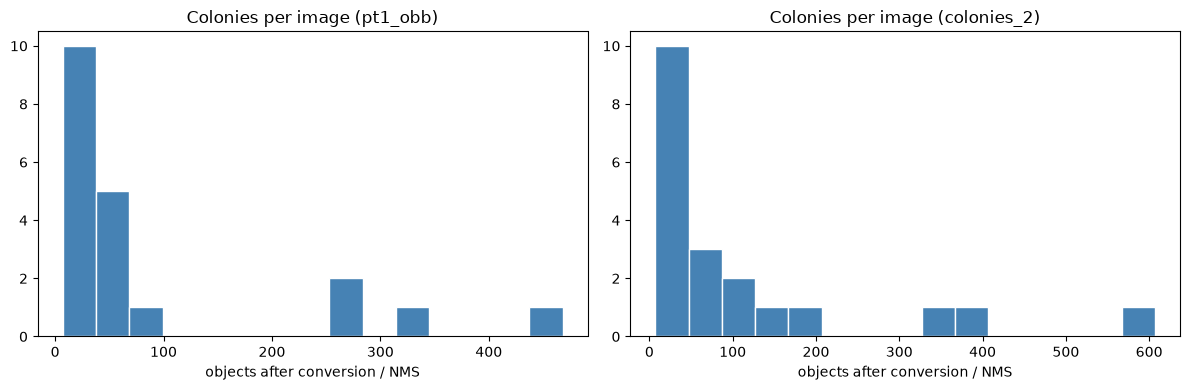

In [6]:
def image_inventory_row(path, source, n_objects, label_ok):
    row = {
        'source': source,
        'file': path.name if path is not None else 'missing',
        'readable': False,
        'label_ok': label_ok,
        'objects': n_objects,
    }
    if path is None or not path.exists():
        row['error'] = 'image file not found'
        return row
    try:
        with Image.open(path) as image:
            array = np.asarray(image)
            row.update({
                'readable': True,
                'format': image.format,
                'mode': image.mode,
                'width': image.width,
                'height': image.height,
                'dtype': str(array.dtype),
                'channels': 1 if array.ndim == 2 else array.shape[-1],
                'min_intensity': float(np.nanmin(array)),
                'max_intensity': float(np.nanmax(array)),
            })
    except Exception as error:
        row['error'] = repr(error)
    return row


inventory_rows = []
pt1_converted = []
for image_path, label_path in pt1_pairs:
    records = parse_obb_label(label_path) if label_path is not None else []
    pt1_converted.append((image_path, records))
    inventory_rows.append(image_inventory_row(
        image_path, 'pt1_obb', len(records), label_path is not None,
    ))

c2_converted = []
for item in c2_pairs:
    c2_converted.append((item['image_path'], item['records'], item['name']))
    inventory_rows.append(image_inventory_row(
        item['image_path'], 'colonies_2', len(item['records']), item['image_path'] is not None,
    ))

inventory = pd.DataFrame(inventory_rows)
display(inventory)
print('Unreadable images:', int((~inventory['readable']).sum()))
print('Images with no objects:', int((inventory['objects'] == 0).sum()))
display(
    inventory.groupby('source')['objects'].agg(['count', 'sum', 'mean', 'min', 'max'])
)

if SHOW_PLOTS:
    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    for axis, source in zip(axes, ('pt1_obb', 'colonies_2')):
        subset = inventory[inventory['source'] == source]
        axis.hist(subset['objects'], bins=15, color='steelblue', edgecolor='white')
        axis.set_title(f'Colonies per image ({source})')
        axis.set_xlabel('objects after conversion / NMS')
    plt.tight_layout()
    plt.show()


## 4. Overlay ground-truth boxes on at least three images

YOLO coordinates are converted back to pixels and drawn on the raw photos. Check that boxes sit on real colonies, not shifted or on the wrong file. We show three images from each CVAT batch.


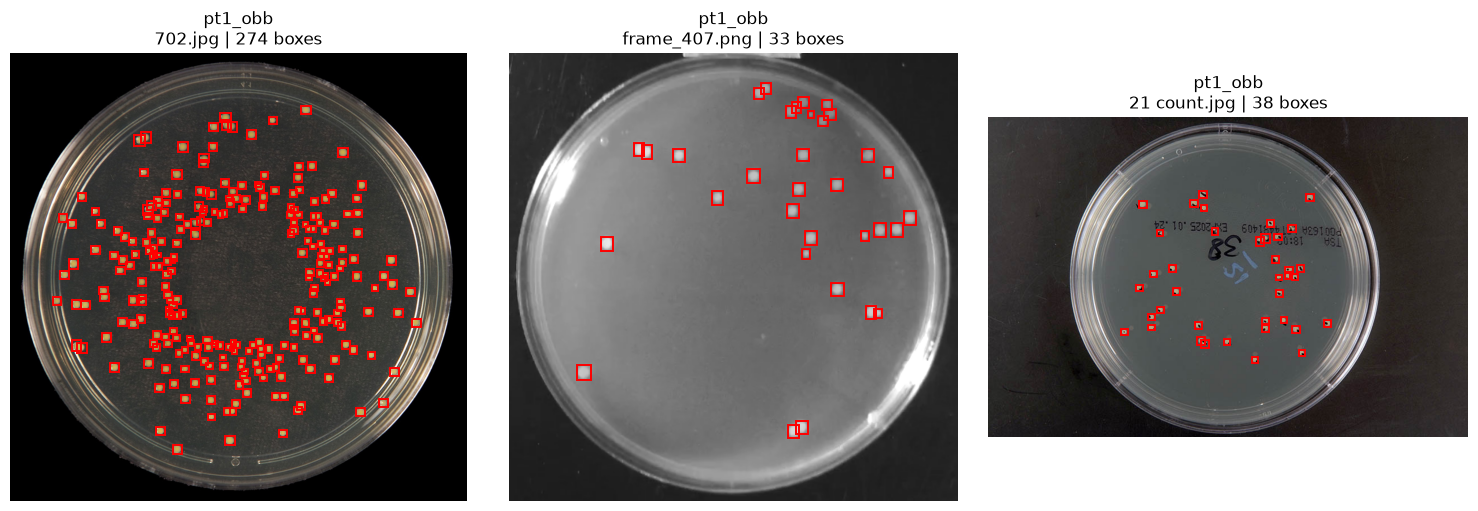

pt1_obb overlaid:
- 702.jpg 274 objects
- frame_407.png 33 objects
- 21 count.jpg 38 objects


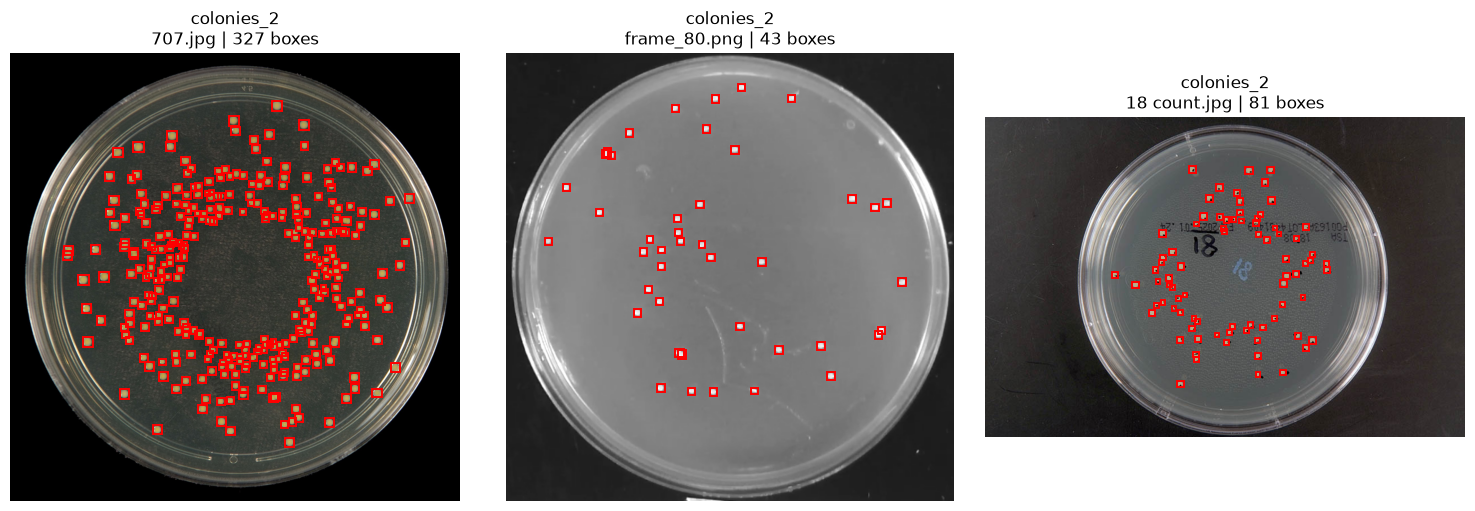

colonies_2 overlaid:
- 707.jpg 327 objects
- frame_80.png 43 objects
- 18 count.jpg 81 objects


In [7]:
def draw_xywh_boxes(axis, image_path, records, title):
    image = np.asarray(Image.open(image_path).convert('RGB'))
    height, width = image.shape[:2]
    axis.imshow(image)
    for _, xc, yc, bw, bh in records:
        x0 = (xc - bw / 2) * width
        y0 = (yc - bh / 2) * height
        axis.add_patch(plt.Rectangle(
            (x0, y0), bw * width, bh * height,
            fill=False, color='red', linewidth=1.4,
        ))
    axis.set_title(f'{title}\n{image_path.name} | {len(records)} boxes')
    axis.axis('off')


def overlay_sample(pairs, source_name, n=3):
    usable = [(path, recs) for path, recs in pairs if path is not None and recs]
    rng = np.random.default_rng(RANDOM_STATE)
    chosen = [usable[i] for i in rng.choice(len(usable), size=min(n, len(usable)), replace=False)]
    figure, axes = plt.subplots(1, len(chosen), figsize=(5 * len(chosen), 5), squeeze=False)
    for axis, (image_path, records) in zip(axes.ravel(), chosen):
        draw_xywh_boxes(axis, image_path, records, source_name)
    plt.tight_layout()
    plt.show()
    print(source_name, 'overlaid:')
    for image_path, records in chosen:
        print('-', image_path.name, len(records), 'objects')


if SHOW_PLOTS:
    overlay_sample(pt1_converted, 'pt1_obb', n=3)
    overlay_sample([(p, r) for p, r, _ in c2_converted], 'colonies_2', n=3)


## 5. Build an Ultralytics dataset

The **validation split is taken only from `pt1_obb`** and then frozen. `colonies_2` is added later to training only. That way the retrain comparison is not confounded by a different val set.


In [8]:
DATASET_ROOT = WORK_ROOT / 'ultralytics'
PT1_ONLY_ROOT = DATASET_ROOT / 'pt1_only'
COMBINED_ROOT = DATASET_ROOT / 'pt1_plus_colonies2'


def reset_dataset(root):
    if root.exists():
        shutil.rmtree(root)
    for split in ('train', 'val'):
        (root / 'images' / split).mkdir(parents=True, exist_ok=True)
        (root / 'labels' / split).mkdir(parents=True, exist_ok=True)


def copy_pair(root, split, image_path, records, prefix):
    stem = f'{prefix}_{sanitize_stem(image_path.name)}'
    dest_image = root / 'images' / split / f'{stem}{image_path.suffix.lower()}'
    dest_label = root / 'labels' / split / f'{stem}.txt'
    shutil.copy2(image_path, dest_image)
    write_yolo_txt(dest_label, records)
    return dest_image, dest_label


def write_yaml(root):
    yaml_path = root / 'colonies.yaml'
    yaml_path.write_text(
        f'path: {root.resolve().as_posix()}\n'
        'train: images/train\n'
        'val: images/val\n'
        'names:\n  0: colony\n',
        encoding='utf-8',
    )
    return yaml_path


rng = np.random.default_rng(RANDOM_STATE)
pt1_usable = [(path, recs) for path, recs in pt1_converted if path is not None]
order = np.arange(len(pt1_usable))
rng.shuffle(order)
n_val = max(3, int(round(0.2 * len(pt1_usable))))
val_idx = set(order[:n_val].tolist())

reset_dataset(PT1_ONLY_ROOT)
pt1_split_rows = []
for index, (image_path, records) in enumerate(pt1_usable):
    split = 'val' if index in val_idx else 'train'
    copy_pair(PT1_ONLY_ROOT, split, image_path, records, 'pt1')
    pt1_split_rows.append({'image': image_path.name, 'split': split, 'objects': len(records)})

pt1_yaml = write_yaml(PT1_ONLY_ROOT)
split_table = pd.DataFrame(pt1_split_rows)
display(split_table.groupby('split').agg(images=('image', 'count'), objects=('objects', 'sum')))
print(pt1_yaml.read_text())

reset_dataset(COMBINED_ROOT)
for index, (image_path, records) in enumerate(pt1_usable):
    split = 'val' if index in val_idx else 'train'
    copy_pair(COMBINED_ROOT, split, image_path, records, 'pt1')
added = 0
for image_path, records, original_name in c2_converted:
    if image_path is None:
        print('Skipping XML image with missing file:', original_name)
        continue
    copy_pair(COMBINED_ROOT, 'train', image_path, records, 'c2')
    added += 1
combined_yaml = write_yaml(COMBINED_ROOT)
print('Added colonies_2 training images:', added)
print('Combined train images:', len(list((COMBINED_ROOT / 'images' / 'train').glob('*'))))
print('Combined val images:', len(list((COMBINED_ROOT / 'images' / 'val').glob('*'))))


,images,objects
split,,
train,16,1337
val,4,556


path: /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_cpu_work/ultralytics/pt1_only
train: images/train
val: images/val
names:
  0: colony

Added colonies_2 training images: 20
Combined train images: 36
Combined val images: 4


## 6. Train YOLO nano on the first CVAT batch

Homework item 2. We train `yolov8n` on `pt1_obb` only, then evaluate the frozen validation split.

CPU-specific choices: `device='cpu'`, `workers=0`, `amp=False`, `mosaic=0`, `imgsz=320`, `batch=2`.


In [9]:
RUNS_ROOT = WORK_ROOT / 'runs'


def train_nano(run_name, data_yaml):
    model = YOLO(YOLO_CHECKPOINT)
    model.train(
        data=str(data_yaml),
        epochs=YOLO_EPOCHS,
        imgsz=YOLO_IMGSZ,
        batch=YOLO_BATCH,
        device=YOLO_DEVICE,
        workers=YOLO_WORKERS,
        amp=False,
        mosaic=0.0,
        mixup=0.0,
        copy_paste=0.0,
        seed=RANDOM_STATE,
        project=str(RUNS_ROOT),
        name=run_name,
        exist_ok=True,
        plots=True,
        verbose=True,
    )
    best_path = RUNS_ROOT / run_name / 'weights' / 'best.pt'
    return best_path if best_path.exists() else None


def evaluate_nano(checkpoint, data_yaml, run_name):
    model = YOLO(str(checkpoint))
    metrics = model.val(
        data=str(data_yaml),
        split='val',
        imgsz=YOLO_IMGSZ,
        device=YOLO_DEVICE,
        workers=YOLO_WORKERS,
        plots=True,
        verbose=False,
        project=str(RUNS_ROOT),
        name=run_name + '_val',
        exist_ok=True,
    )
    return model, pd.DataFrame([{
        'run': run_name,
        'checkpoint': str(checkpoint),
        'precision': float(metrics.box.mp),
        'recall': float(metrics.box.mr),
        'mAP50': float(metrics.box.map50),
        'mAP50-95': float(metrics.box.map),
        'n_val_images': len(list((Path(data_yaml).parent / 'images' / 'val').glob('*'))),
    }])


baseline_best = RUNS_ROOT / 'pt1_yolov8n' / 'weights' / 'best.pt'
if RUN_TRAINING:
    trained = train_nano('pt1_yolov8n', pt1_yaml)
    if trained is not None:
        baseline_best = trained
    print('Baseline checkpoint:', baseline_best)
else:
    print('Training skipped. Set RUN_TRAINING=True to train.')


New https://pypi.org/project/ultralytics/8.4.218 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.182 🚀 Python-3.11.16 torch-2.14.1+cu130 CPU (13th Gen Intel Core i7-13700H)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_cpu_work/ultralytics/pt1_only/colonies.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=N

2026/11/24 13:44:09 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/24 13:44:09 INFO mlflow.store.db.utils: Updating database tables
2026/11/24 13:44:11 INFO mlflow.tracking.fluent: Experiment with name '/home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_cpu_work/runs' does not exist. Creating a new experiment.


MLflow: logging run_id(19a1c337f2b747ed9e98f0b3386dc991) to sqlite:////home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/mlflow.db
MLflow: disable with 'yolo settings mlflow=False'
Using 16 train, 4 val images for fraction=1.0 at imgsz=320
Using 0 dataloader workers
Logging results to /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_cpu_work/runs/pt1_yolov8n
Starting training for 10 epochs...
Closing dataloader mosaic

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/10         0G      3.667      4.782      1.218         55        320: 100% ━━━━━━━━━━━━ 8/8 6.5it/s 1.2s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 5.8it/s 0.2s
                   all          4        556          0          0          0          0

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/10         0G      3.266      

In [10]:
metrics_table = pd.DataFrame()
baseline_model = None
if baseline_best.exists():
    baseline_model, baseline_metrics = evaluate_nano(baseline_best, pt1_yaml, 'pt1_yolov8n')
    metrics_table = baseline_metrics
    display(metrics_table)
else:
    print('No baseline checkpoint yet.')


Ultralytics 8.4.182 🚀 Python-3.11.16 torch-2.14.1+cu130 CPU (13th Gen Intel Core i7-13700H)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2555.3±1259.9 MB/s, size: 237.1 KB)
val: Scanning /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_cpu_work/ultralytics/pt1_only/labels/val.cache... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 2.8Mit/s 0.0s
WARNING ⚠️ Dataset images contain up to 468 objects (val=468), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=468 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 10.7it/s 0.1s
                   all          4        556    0.00241     0.0054   2.01e-05   5.22e-06
Speed:

,run,checkpoint,precision,recall,mAP50,mAP50-95,n_val_images
0,pt1_yolov8n,/home/nikolaieva/ML/KSE_ML_for_bioinformatics/...,0.00241,0.005396,0.00002,0.000005,4


## 7. Visual check: ground truth vs prediction

Look at missed colonies, extra boxes, and loose boundaries. That is homework question 3.


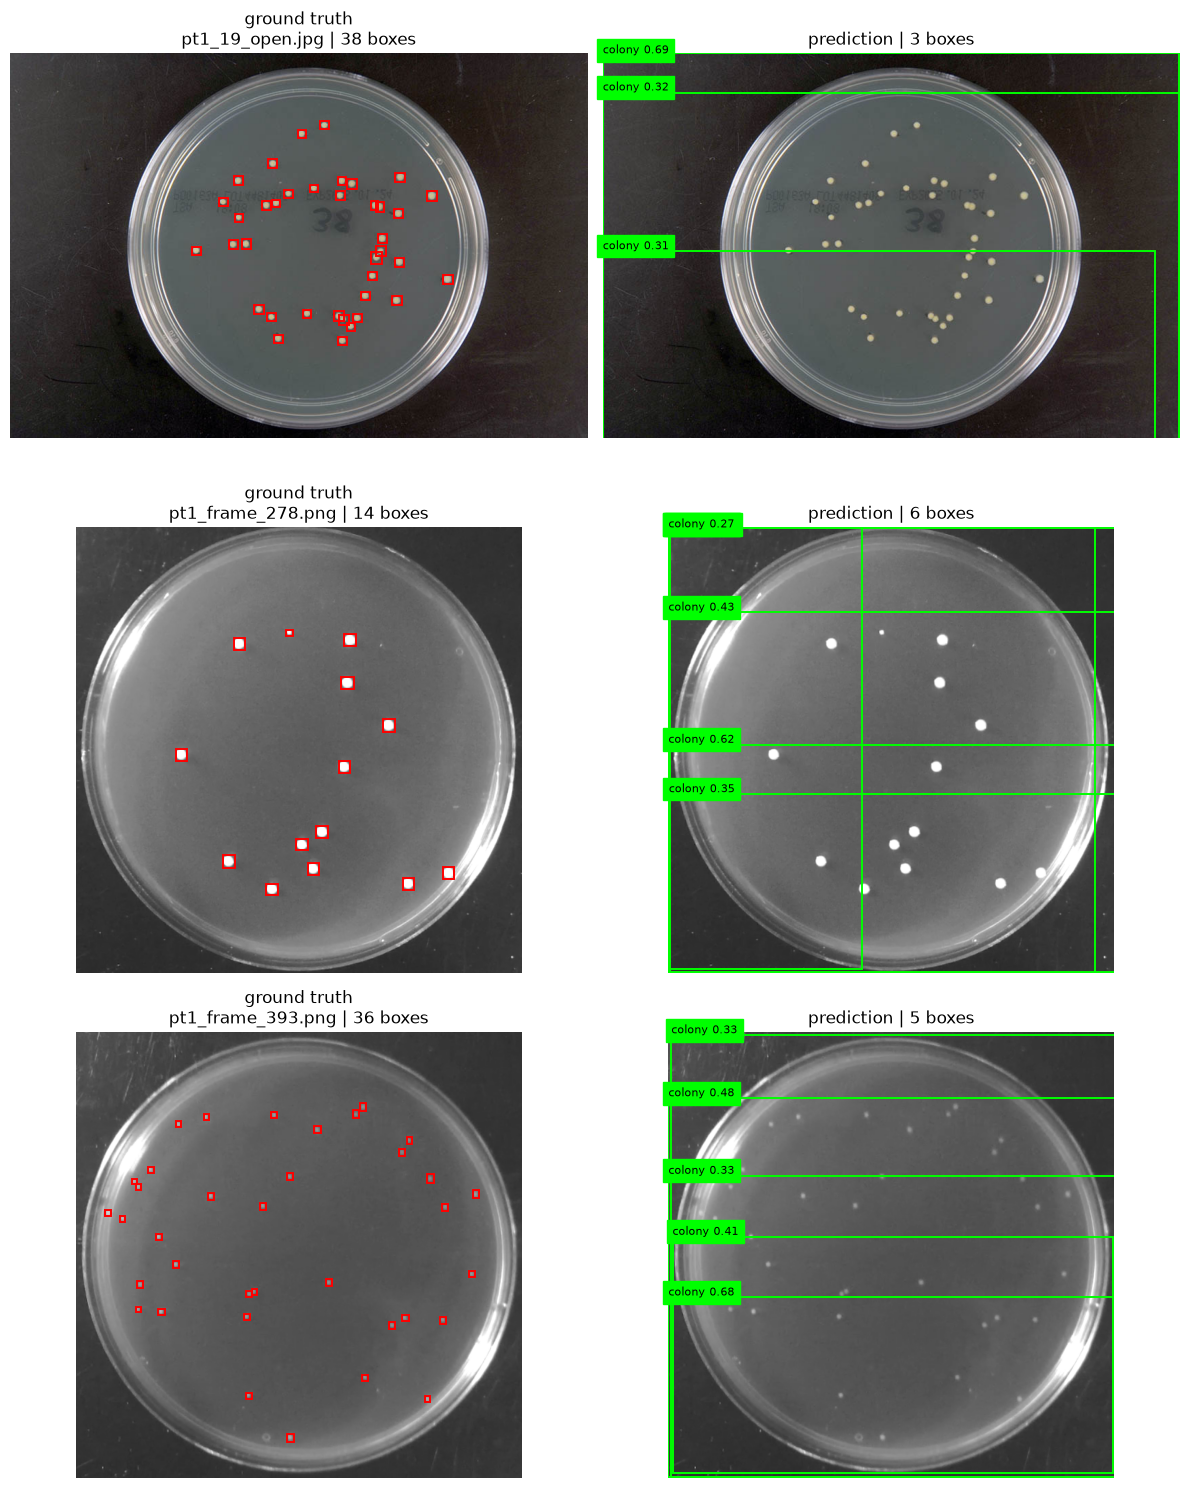

In [11]:
def boxes_from_result(result):
    if result.boxes is None or len(result.boxes) == 0:
        return np.empty((0, 4)), np.empty(0, dtype=int), np.empty(0)
    return (
        result.boxes.xyxy.detach().cpu().numpy(),
        result.boxes.cls.detach().cpu().numpy().astype(int),
        result.boxes.conf.detach().cpu().numpy(),
    )


val_images = sorted((PT1_ONLY_ROOT / 'images' / 'val').glob('*'))
if baseline_model is not None and val_images and SHOW_PLOTS:
    chosen = val_images[: min(3, len(val_images))]
    figure, axes = plt.subplots(len(chosen), 2, figsize=(12, 5 * len(chosen)), squeeze=False)
    for row, image_path in enumerate(chosen):
        label_path = PT1_ONLY_ROOT / 'labels' / 'val' / f'{image_path.stem}.txt'
        records = parse_obb_label(label_path) if label_path.exists() else []
        image = np.asarray(Image.open(image_path).convert('RGB'))
        draw_xywh_boxes(axes[row, 0], image_path, records, 'ground truth')
        result = baseline_model.predict(
            image, imgsz=YOLO_IMGSZ, conf=0.25, device=YOLO_DEVICE, verbose=False,
        )[0]
        boxes, classes, confs = boxes_from_result(result)
        axes[row, 1].imshow(image)
        for box, conf in zip(boxes, confs):
            x0, y0, x1, y1 = box
            axes[row, 1].add_patch(plt.Rectangle(
                (x0, y0), x1 - x0, y1 - y0, fill=False, color='lime', linewidth=1.4,
            ))
            axes[row, 1].text(x0, max(0, y0 - 3), f'colony {conf:.2f}', color='black', fontsize=8, backgroundcolor='lime')
        axes[row, 1].set_title(f'prediction | {len(boxes)} boxes')
        axes[row, 1].axis('off')
    plt.tight_layout()
    plt.show()
else:
    print('Visual prediction check skipped.')


## 8. Retrain after adding `colonies_2`

Homework item 3. The second CVAT zip is additional labelled training data. Validation images stay exactly those held out from `pt1_obb`.


In [12]:
retrained_best = RUNS_ROOT / 'pt1_plus_c2_yolov8n' / 'weights' / 'best.pt'
retrained_model = None
if RUN_TRAINING:
    trained = train_nano('pt1_plus_c2_yolov8n', combined_yaml)
    if trained is not None:
        retrained_best = trained
    print('Retrained checkpoint:', retrained_best)
else:
    print('Retraining skipped.')

if retrained_best.exists():
    retrained_model, retrained_metrics = evaluate_nano(
        retrained_best, combined_yaml, 'pt1_plus_c2_yolov8n',
    )
    metrics_table = pd.concat([metrics_table, retrained_metrics], ignore_index=True)
    display(metrics_table)
    out_csv = WEEK7_ROOT / 'homework' / 'detection_metrics_cpu.csv'
    metrics_table.to_csv(out_csv, index=False)
    print('Saved:', out_csv)
else:
    print('No retrained checkpoint yet.')


New https://pypi.org/project/ultralytics/8.4.218 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.182 🚀 Python-3.11.16 torch-2.14.1+cu130 CPU (13th Gen Intel Core i7-13700H)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_cpu_work/ultralytics/pt1_plus_colonies2/colonies.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, li

,run,checkpoint,precision,recall,mAP50,mAP50-95,n_val_images
0,pt1_yolov8n,/home/nikolaieva/ML/KSE_ML_for_bioinformatics/...,0.002410,0.005396,0.000020,0.000005,4
1,pt1_plus_c2_yolov8n,/home/nikolaieva/ML/KSE_ML_for_bioinformatics/...,0.283801,0.106115,0.085675,0.029253,4


Saved: /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/detection_metrics_cpu.csv


## Report answers

Fill these after the training cells finish.

**Image / annotation / split checks**

- `pt1_obb.zip`: YOLO OBB (9 numbers) converted to 5-number detect boxes.
- `colonies_2.zip`: CVAT XML boxes + polygons converted the same way; overlapping imported polygons were NMS-merged with manual boxes.
- Pairing, `[0, 1]` coordinates and overlays were checked before training.
- Val split: 20% of the first zip only, frozen when the second zip was added.

**YOLO nano metrics**

Copy the table printed above (precision, recall, mAP50, mAP50-95) for:

- baseline = `pt1_obb` only
- retrained = `pt1_obb` + `colonies_2`

**Most common errors**

After the GT vs prediction figure: missed colonies / false boxes / loose boundaries = ...

**Did extra CVAT labels help?**

Compare the two rows of the metrics table. The val images did not change, so any gain/loss comes from the extra training labels.
